In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.metrics.cluster import adjusted_rand_score

import service
from clustering.KMeans import KMeans
from clustering.KMedoids import KMedoids
from clustering.DBSCAN import DBSCAN
from clustering.AgglomerativeClustering import AgglomerativeClustering

In [2]:
sns.set_style('darkgrid')

In [3]:
df = pd.read_csv('data/data_1.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   x       10 non-null     int64 
 1   y       10 non-null     int64 
 2   label   10 non-null     object
dtypes: int64(2), object(1)
memory usage: 368.0+ bytes


In [4]:
X, labels = df.drop(columns='label'), df['label']
X.shape, labels.shape

((10, 2), (10,))

In [5]:
X = X[['x', 'y']].to_numpy()

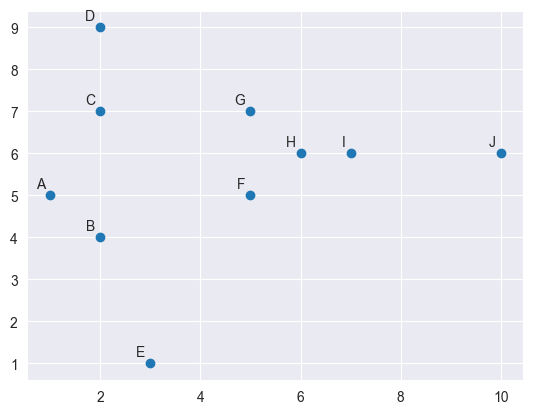

In [6]:
service.plot_raw_data(X, labels)

#### KMeans

In [7]:
n_clusters = 3  # TODO change to variant
init = [[1, 5], [5, 5], [10, 6]]
max_iter = 10
random_state = 42

In [8]:
clusterer = KMeans(
    n_clusters=n_clusters,
    init=init,
    max_iter=max_iter,
    random_state=random_state,
)
clusterer.fit(X);

In [9]:
clusterer.n_iter_

2

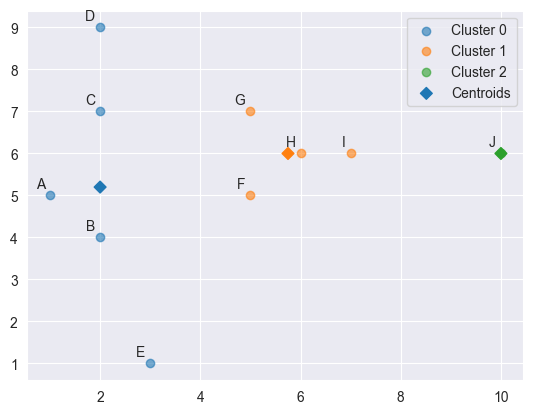

In [10]:
service.plot_clusters(
    X,
    labels=labels,
    cluster_labels=clusterer.labels_,
    cluster_centers=clusterer.cluster_centers_,
)

Compare with similar `scikit-learn` model

In [11]:
sk_clusterer = sklearn.cluster.KMeans(
    n_clusters=n_clusters,
    init=init,
    max_iter=max_iter,
    random_state=random_state,
)
sk_clusterer.fit(X);

In [12]:
sk_clusterer.n_iter_

2

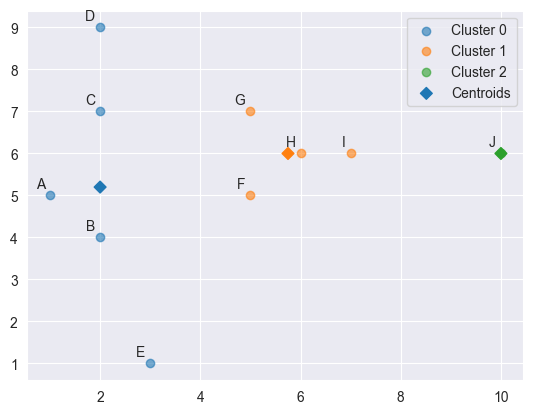

In [13]:
service.plot_clusters(
    X,
    labels=labels,
    cluster_labels=sk_clusterer.labels_,
    cluster_centers=sk_clusterer.cluster_centers_,
)

In [14]:
assert adjusted_rand_score(clusterer.labels_, sk_clusterer.labels_) == 1.0
assert np.allclose(clusterer.inertia_, sk_clusterer.inertia_)

#### KMedoids

In [15]:
n_clusters = 3  # TODO change to variant
init = [[5, 5], [5, 7], [6, 6]]
max_iter = 10
random_state = 42

In [16]:
clusterer = KMedoids(
    n_clusters=n_clusters,
    init=init,
    max_iter=max_iter,
    random_state=random_state,
)
clusterer.fit(X);

In [17]:
clusterer.n_iter_

2

In [18]:
clusterer.cluster_center_indices_

array([1, 2, 8])

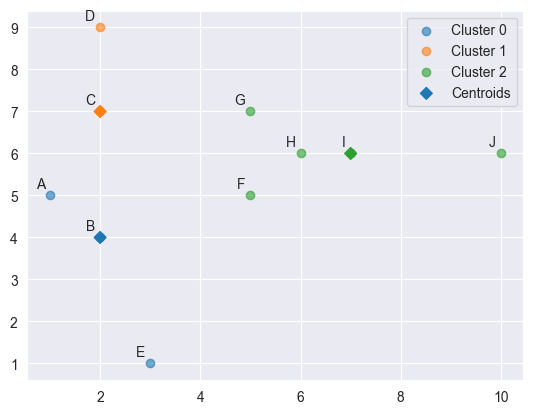

In [19]:
service.plot_clusters(
    X,
    labels=labels,
    cluster_labels=clusterer.labels_,
    cluster_centers=clusterer.cluster_centers_,
)

#### DBSCAN

In [20]:
eps = 2.5  # TODO change to variant
min_samples = 3

In [21]:
clusterer = DBSCAN(
    eps=eps,
    min_samples=min_samples,
)
clusterer.fit(X);

In [22]:
clusterer.core_sample_indices_

array([0, 2, 5, 6, 7, 8])

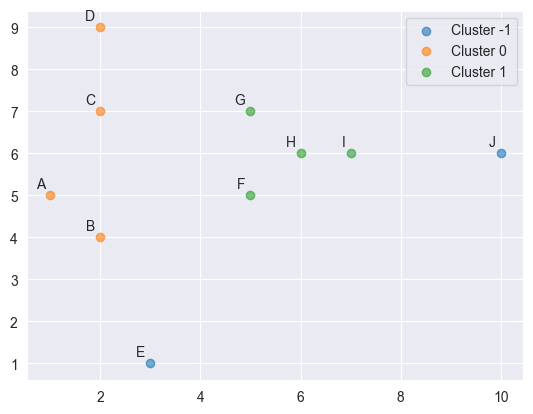

In [23]:
service.plot_clusters(
    X,
    labels=labels,
    cluster_labels=clusterer.labels_,
)

Compare with similar `scikit-learn` model

In [24]:
sk_clusterer = sklearn.cluster.DBSCAN(
    eps=eps,
    min_samples=min_samples,
)
sk_clusterer.fit(X);

In [25]:
sk_clusterer.core_sample_indices_

array([0, 2, 5, 6, 7, 8])

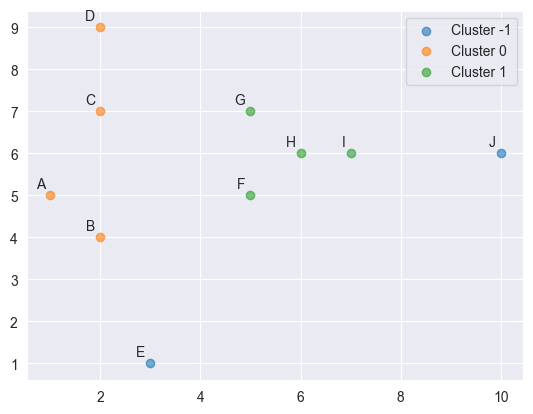

In [26]:
service.plot_clusters(
    X,
    labels=labels,
    cluster_labels=sk_clusterer.labels_,
)

In [27]:
assert adjusted_rand_score(clusterer.labels_, sk_clusterer.labels_) == 1.0

#### AgglomerativeClustering

In [28]:
n_clusters = 3  # TODO change to variant

##### linkage='single'

In [29]:
linkage = 'single'

In [30]:
clusterer = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage=linkage,
)
clusterer.fit(X);

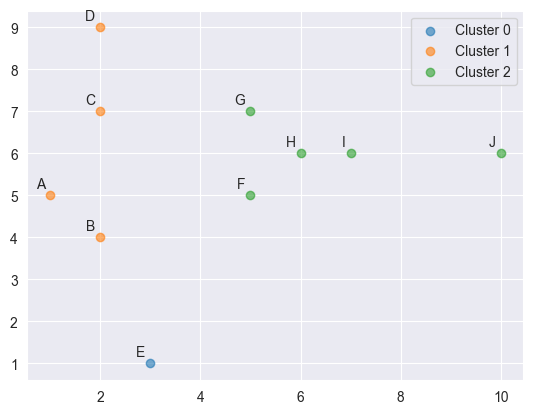

In [31]:
service.plot_clusters(
    X,
    labels=labels,
    cluster_labels=clusterer.labels_,
)

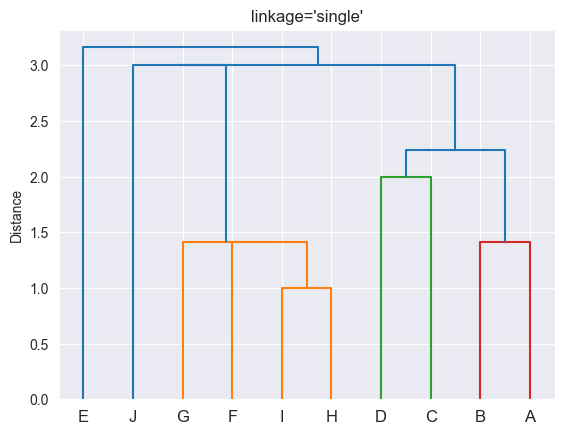

In [32]:
service.plot_dendrogram(
    children=clusterer.children_,
    distances=clusterer.distances_,
    labels=labels.to_numpy(),
    title=f"linkage='{linkage}'",
)

Compare with similar `scikit-learn` model

In [33]:
sk_clusterer = sklearn.cluster.AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage=linkage,
    compute_distances=True,
)
sk_clusterer.fit(X);

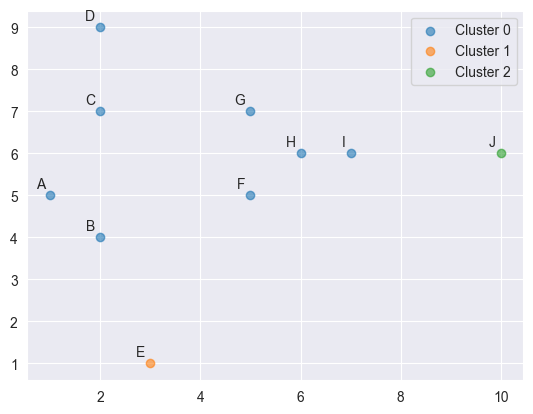

In [34]:
service.plot_clusters(
    X,
    labels=labels,
    cluster_labels=sk_clusterer.labels_,
)

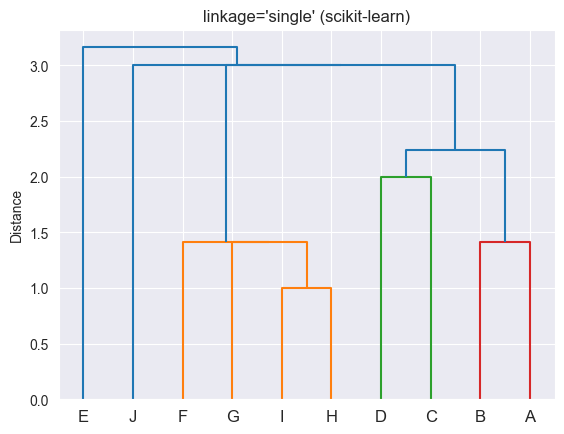

In [35]:
service.plot_dendrogram(
    children=sk_clusterer.children_,
    distances=sk_clusterer.distances_,
    labels=labels.to_numpy(),
    title=f"linkage='{linkage}' (scikit-learn)",
)

In [36]:
assert np.allclose(clusterer.distances_, sk_clusterer.distances_)

##### linkage='complete'

In [37]:
linkage = 'complete'

In [38]:
clusterer = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage=linkage,
)
clusterer.fit(X);

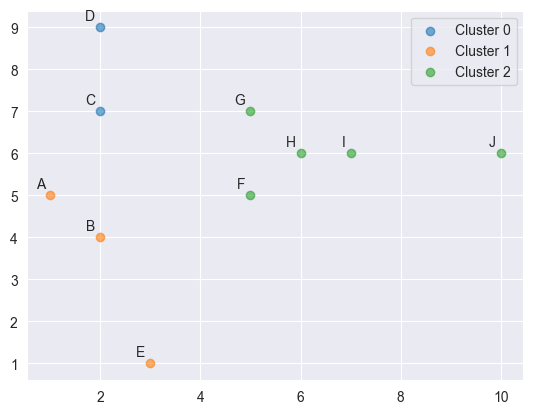

In [39]:
service.plot_clusters(
    X,
    labels=labels,
    cluster_labels=clusterer.labels_,
)

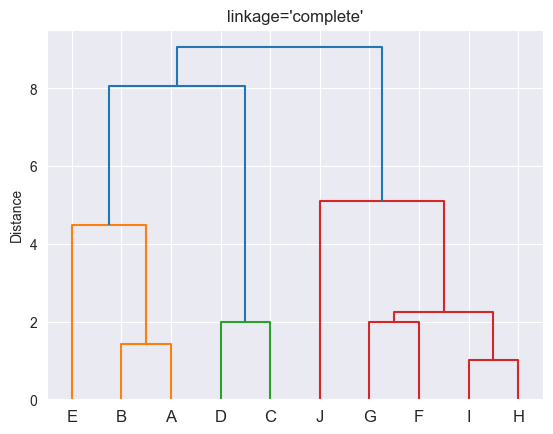

In [40]:
service.plot_dendrogram(
    children=clusterer.children_,
    distances=clusterer.distances_,
    labels=labels.to_numpy(),
    title=f"linkage='{linkage}'",
)

Compare with similar `scikit-learn` model

In [41]:
sk_clusterer = sklearn.cluster.AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage=linkage,
    compute_distances=True,
)
sk_clusterer.fit(X);

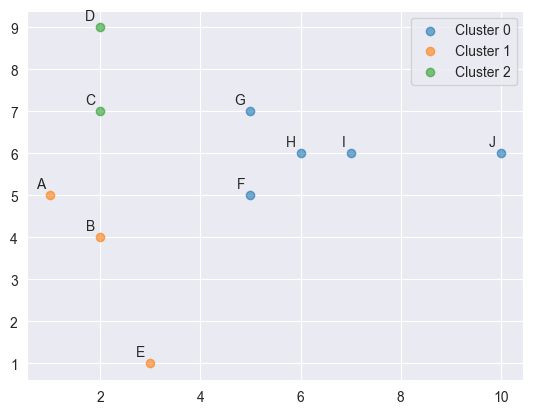

In [42]:
service.plot_clusters(
    X,
    labels=labels,
    cluster_labels=sk_clusterer.labels_,
)

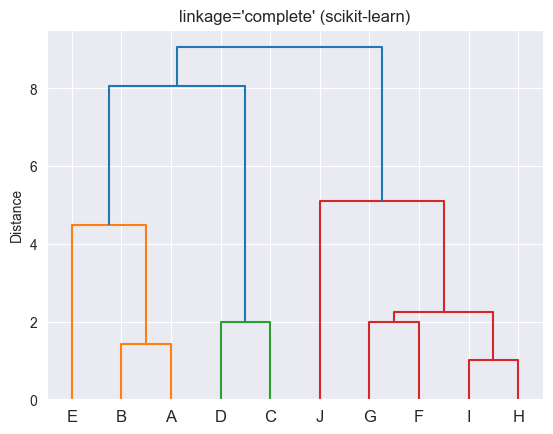

In [43]:
service.plot_dendrogram(
    children=sk_clusterer.children_,
    distances=sk_clusterer.distances_,
    labels=labels.to_numpy(),
    title=f"linkage='{linkage}' (scikit-learn)",
)

In [44]:
assert np.allclose(clusterer.distances_, sk_clusterer.distances_)